# Capítulo 2. Ecuaciones de primer orden
## Sección 2.3.1. Ecuaciones cuasilineales y sistema característico

**Fuente principal:** página 6 de `Ecuacione Lineales De Primer Orden.pdf`.

Se estudia

$$
a(x,y,u)u_x+b(x,y,u)u_y=c(x,y,u).
$$

### Ejemplo gráfico complementario · Pérdida de invertibilidad

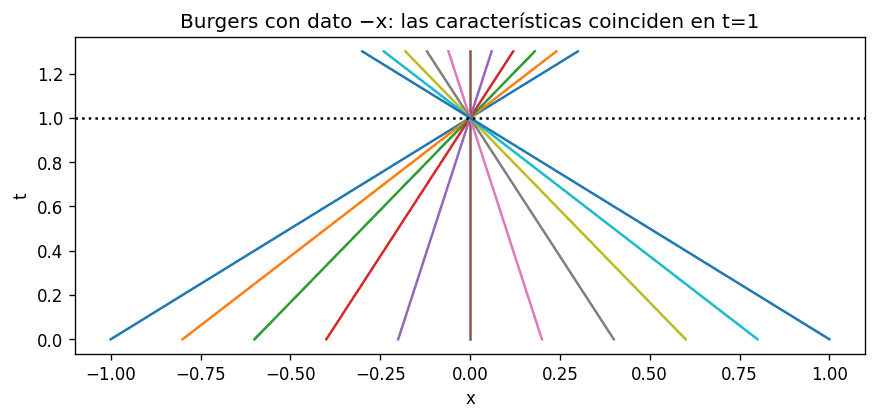

In [1]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7.4,3.6))
t=np.linspace(0,1.3,160)
for a in np.linspace(-1,1,11):
    ax.plot(a*(1-t),t)
ax.axhline(1,color="black",ls=":")
ax.set(xlabel="x",ylabel="t",title="Burgers con dato −x: las características coinciden en t=1")
fig.tight_layout()
plt.show()

# 2.3.1. Transcripción organizada de las notas

Las notas distinguen:

- ecuaciones lineales;
- ecuaciones semilineales;
- ecuaciones cuasilineales.

La función $u$ se conoce sobre una curva

$$
\Gamma
=
\left\{
(\widetilde x(\xi),\widetilde y(\xi)):
\xi\in I
\right\}
$$

mediante

$$
u(\widetilde x(\xi),\widetilde y(\xi))
=
f(\xi).
$$

La curva levantada es

$$
\Gamma_0
=
\left\{
(\widetilde x(\xi),\widetilde y(\xi),f(\xi)):
\xi\in I
\right\}.
$$

El sistema característico es

$$
\frac{dx}{ds}=a(x,y,u),
$$

$$
\frac{dy}{ds}=b(x,y,u),
$$

$$
\frac{du}{ds}=c(x,y,u).
$$

# 2.3.2. Formulación formal

## Definición 2.3.1 — Ecuación cuasilineal

Una ecuación cuasilineal de primer orden tiene la forma

$$
a(x,y,u)u_x+b(x,y,u)u_y=c(x,y,u).
$$

## Definición 2.3.2 — Datos de Cauchy

Los datos se prescriben por

$$
u(\widetilde x(\xi),\widetilde y(\xi))=f(\xi).
$$

## Definición 2.3.3 — Sistema característico

Para cada $\xi$ se resuelve

$$
\begin{cases}
x_s=a(x,y,z),\\
y_s=b(x,y,z),\\
z_s=c(x,y,z),
\end{cases}
$$

con

$$
x(0,\xi)=\widetilde x(\xi),
$$

$$
y(0,\xi)=\widetilde y(\xi),
$$

$$
z(0,\xi)=f(\xi).
$$

## Proposición 2.3.4 — Compatibilidad con la EDP

Si

$$
z(s)=u(x(s),y(s)),
$$

entonces

$$
z'(s)
=
u_xx'(s)+u_yy'(s)
=
a u_x+b u_y
=
c.
$$

## Aclaración 2.3.5 — Interpretación geométrica

Sea

$$
V=(a,b,c).
$$

Un vector normal a la gráfica de $u$ es

$$
N=(-u_x,-u_y,1).
$$

La EDP equivale a

$$
V\cdot N=0.
$$

Por tanto, el campo característico es tangente a la superficie solución.

## Resultado añadido 2.3.6 — Superficie característica

La familia

$$
\Sigma(s,\xi)
=
(x(s,\xi),y(s,\xi),z(s,\xi))
$$

genera una superficie. Para recuperar una función $u(x,y)$ debe poder invertirse localmente el mapa

$$
(s,\xi)\longmapsto(x(s,\xi),y(s,\xi)).
$$

# 2.3.3. Ejemplos

## Ejemplo 2.3.7 — Ecuación semilineal

Para

$$
u_x+u_y=u,
$$

el sistema es

$$
x'=1,
$$

$$
y'=1,
$$

$$
z'=z.
$$

Así,

$$
x=x_0+s,
$$

$$
y=y_0+s,
$$

$$
z=z_0e^s.
$$

## Ejemplo 2.3.8 — Burgers

Para

$$
u_t+u u_x=0,
$$

se obtiene

$$
x'=z,
$$

$$
t'=1,
$$

$$
z'=0.
$$

# 2.3.4. Visualización Manim

Se visualiza la superficie generada por las características de

$$
u_x+u_y=u
$$

con dato

$$
u(\xi,0)=\sin\xi.
$$

Las características son

$$
x=\xi+s,
$$

$$
y=s,
$$

$$
u=e^s\sin\xi.
$$

La curva inicial y los ejes permanecen visibles durante cuatro segundos.

In [ ]:
import os
import shutil
import tempfile
import uuid
from pathlib import Path

def miktex_candidates():
    candidates = []
    for base in (
        os.environ.get("LOCALAPPDATA"),
        os.environ.get("ProgramFiles"),
        os.environ.get("ProgramFiles(x86)"),
    ):
        if not base:
            continue
        root = Path(base)
        candidates.extend([
            root / "Programs" / "MiKTeX" / "miktex" / "bin" / "x64",
            root / "Programs" / "MiKTeX" / "miktex" / "bin",
            root / "MiKTeX" / "miktex" / "bin" / "x64",
            root / "MiKTeX" / "miktex" / "bin",
        ])
    return candidates

for candidate in miktex_candidates():
    if candidate.exists():
        os.environ["PATH"] = (
            str(candidate)
            + os.pathsep
            + os.environ.get("PATH", "")
        )

latex_exe = shutil.which("latex")
dvisvgm_exe = shutil.which("dvisvgm")

if latex_exe is None or dvisvgm_exe is None:
    raise RuntimeError(
        "No se encontraron latex.exe y dvisvgm.exe. "
        "Abre MiKTeX Console, completa la instalación y reinicia el kernel."
    )

from manim import config, __version__ as manim_version

TEX_RUNTIME_DIR = (
    Path(tempfile.gettempdir())
    / f"manim_tex_recuperado_{os.getpid()}_{uuid.uuid4().hex[:10]}"
)
TEX_RUNTIME_DIR.mkdir(parents=True, exist_ok=True)

config.no_latex_cleanup = True
config.tex_dir = str(TEX_RUNTIME_DIR)
config.media_embed = True
config.media_width = "100%"

print(f"Manim Community: {manim_version}")
print("latex   :", latex_exe)
print("dvisvgm :", dvisvgm_exe)
print("TeX dir :", TEX_RUNTIME_DIR)
print("Render preparado: 2560×1440, 120 fps")
print("La animación no ha sido compilada.")

In [ ]:
%%manim -v WARNING -r 2560,1440 --fps 120 SuperficieCuasilineal

from manim import *
import numpy as np

config.no_latex_cleanup = True
config.tex_dir = str(TEX_RUNTIME_DIR)
config.media_embed = True
config.media_width = "100%"


class SuperficieCuasilineal(ThreeDScene):
    def construct(self):
        self.camera.background_color = "#0B1020"
        self.set_camera_orientation(
            phi=68 * DEGREES,
            theta=-46 * DEGREES,
            zoom=0.82,
        )

        title = Text(
            "Superficie solución generada por características",
            font_size=38,
            weight=BOLD,
        ).to_edge(UP, buff=0.18)

        equation = MathTex(
            r"u_x+u_y=u",
            r"\qquad",
            r"(x,y,u)=(\xi+s,s,e^s\sin\xi)",
            font_size=32,
            color=YELLOW_C,
        ).next_to(title, DOWN, buff=0.12)

        axes = ThreeDAxes(
            x_range=[-4, 4, 1],
            y_range=[0, 2.2, 0.5],
            z_range=[-4, 4, 1],
            x_length=7.0,
            y_length=4.0,
            z_length=5.2,
        )

        initial_curve = ParametricFunction(
            lambda xi: axes.c2p(xi, 0.0, np.sin(xi)),
            t_range=[-3.0, 3.0],
            color=ORANGE,
            stroke_width=6,
        )

        surface = Surface(
            lambda xi, s: axes.c2p(
                xi + s,
                s,
                np.exp(s) * np.sin(xi),
            ),
            u_range=[-3.0, 3.0],
            v_range=[0.0, 1.4],
            resolution=(36, 18),
            fill_opacity=0.30,
            checkerboard_colors=[BLUE_D, BLUE_E],
            stroke_width=0.6,
        )

        xi_values = np.linspace(-2.7, 2.7, 9)
        characteristic_curves = VGroup(*[
            ParametricFunction(
                lambda s, xi=xi: axes.c2p(
                    xi + s,
                    s,
                    np.exp(s) * np.sin(xi),
                ),
                t_range=[0.0, 1.4],
                color=TEAL_C,
                stroke_width=3,
            )
            for xi in xi_values
        ])

        tracker = ValueTracker(0.0)

        particles = VGroup(*[
            Dot3D(
                axes.c2p(xi, 0.0, np.sin(xi)),
                radius=0.065,
                color=PINK,
            )
            for xi in xi_values
        ])

        for dot, xi in zip(particles, xi_values):
            dot.add_updater(
                lambda mob, xi=xi: mob.move_to(
                    axes.c2p(
                        xi + tracker.get_value(),
                        tracker.get_value(),
                        np.exp(tracker.get_value()) * np.sin(xi),
                    )
                )
            )

        s_number = DecimalNumber(
            0.0,
            num_decimal_places=2,
            font_size=30,
            color=GREEN_C,
        )
        s_number.add_updater(
            lambda mob: mob.set_value(tracker.get_value())
        )

        display = VGroup(
            MathTex(r"s=", font_size=30, color=GREEN_C),
            s_number,
        ).arrange(RIGHT, buff=0.05).to_corner(UL, buff=0.35)
        self.add_fixed_in_frame_mobjects(title, equation, display)

        self.play(
            FadeIn(title),
            Write(equation),
            Create(axes),
            Create(initial_curve),
            FadeIn(surface),
            LaggedStart(
                *[Create(curve) for curve in characteristic_curves],
                lag_ratio=0.06,
            ),
            FadeIn(particles),
            FadeIn(display),
            run_time=3.2,
        )

        self.wait(4.0)

        self.play(
            tracker.animate.set_value(1.4),
            run_time=12.0,
            rate_func=linear,
        )

        self.wait(3.0)

        for dot in particles:
            dot.clear_updaters()
        s_number.clear_updaters()

# 2.3.5. Ejercicios propuestos

1. Clasifique como lineal, semilineal o cuasilineal:
   $$
   (1+x^2)u_x+e^yu_y=u,
   $$
   $$
   u_x+u_y=u^2,
   $$
   $$
   uu_x+yu_y=x.
   $$

2. Resuelva el sistema característico de
   $$
   u_x+2u_y=3u.
   $$

3. Para
   $$
   u_x+yu_y=0,
   $$
   con datos $u(\xi,1)=f(\xi)$, construya la curva levantada.

4. Demuestre geométricamente que $V=(a,b,c)$ es tangente a la gráfica exactamente cuando $a u_x+b u_y=c$.

# Revisión

Se recuperaron la clasificación, la curva inicial, el sistema tridimensional, la interpretación geométrica y una visualización 3D.

La siguiente sección lógica estudia la transversalidad y la existencia local.